# Minimum Wage Policy and Business Formation
**Evidence from a 30-state panel, 2004 onward**

Habib Gul Ahmadzai

## Overview

This notebook estimates whether state minimum wage increases change the rate of new business formation. It uses a state-by-year panel of 30 U.S. states, with all data pulled from FRED.

## How to run

1. Get a free API key from FRED (fred.stlouisfed.org) and paste it into the second code cell where it says `YOUR_FRED_API_KEY_HERE`.
2. Go to Runtime -> Run all.
3. It takes a few minutes, because the notebook downloads several series for each of the 30 states.

## Approach

- **Main model:** state and year fixed effects, so differences that never change within a state and shocks that hit every state in a given year do not drive the results.
- **Standard errors:** clustered by state. With only about 30 clusters, I treat the p-values with some caution.
- **Robustness checks:** a lagged minimum wage, state-specific time trends, and a placebo test using future minimum wage increases. If next year's increase "predicts" this year's business applications, that points to reverse causality.

## Limitation

This is observational state-level data, not an experiment. States choose their own minimum wages, so these checks make the estimates more credible but do not prove the effect is causal.

## Data

Everything comes from FRED. The series IDs follow a state-abbreviation pattern:

| Variable | Pattern | Example |
|----------|---------|---------|
| State minimum wage | `STTMINWG[XX]` | `STTMINWGCA` |
| Federal minimum wage (fallback) | `FEDMINNFRWG` | n/a |
| Business applications | `BABATOTALNSA[XX]` | `BABATOTALNSACA` |
| High-propensity applications | `BAHBATOTALNSA[XX]` | `BAHBATOTALNSACA` |
| Real GDP | `[XX]RGSP` | `CARGSP` |
| Unemployment rate | `[XX]UR` | `CAUR` |
| Per capita income | `[XX]PCPI` | `CAPCPI` |
| Population | `[XX]POP` | `CAPOP` |


In [ ]:
# Packages and imports
!pip install fredapi --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from fredapi import Fred
import time, warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
print('Packages loaded.')


Packages loaded.


In [ ]:
# FRED API key
FRED_API_KEY = "YOUR_FRED_API_KEY_HERE"

fred = Fred(api_key=FRED_API_KEY)
try:
    fred.get_series("FEDFUNDS", limit=1)
    print("FRED API key works.")
except Exception as e:
    print(f"Key error: {e}")

FRED API key works!


In [ ]:
# State list and FRED series IDs
# The sample keeps the original 20 states and adds 10 more large/diverse
# states to improve cluster count and geographic/policy variation.

states = [
    "California", "Texas", "New York", "Florida", "Illinois",
    "Georgia", "North Carolina", "Pennsylvania", "Ohio", "Michigan",
    "New Jersey", "Virginia", "Washington", "Arizona", "Massachusetts",
    "Tennessee", "Indiana", "Missouri", "Wisconsin", "Colorado",
    "Alabama", "Kentucky", "Louisiana", "Maryland", "Minnesota",
    "Nevada", "Oklahoma", "Oregon", "South Carolina", "Utah"
]

STATE_ABBR = {
    "California": "CA",
    "Texas": "TX",
    "New York": "NY",
    "Florida": "FL",
    "Illinois": "IL",
    "Georgia": "GA",
    "North Carolina": "NC",
    "Pennsylvania": "PA",
    "Ohio": "OH",
    "Michigan": "MI",
    "New Jersey": "NJ",
    "Virginia": "VA",
    "Washington": "WA",
    "Arizona": "AZ",
    "Massachusetts": "MA",
    "Tennessee": "TN",
    "Indiana": "IN",
    "Missouri": "MO",
    "Wisconsin": "WI",
    "Colorado": "CO",
    "Alabama": "AL",
    "Kentucky": "KY",
    "Louisiana": "LA",
    "Maryland": "MD",
    "Minnesota": "MN",
    "Nevada": "NV",
    "Oklahoma": "OK",
    "Oregon": "OR",
    "South Carolina": "SC",
    "Utah": "UT",
}

# These states have no state-level minimum wage law in the sample design.
# They are assigned the federal minimum wage floor in the minimum wage section.
NO_STATE_MW = {"Alabama", "Louisiana", "South Carolina", "Tennessee"}

abbr = STATE_ABBR
MW_IDS  = {s: (None if s in NO_STATE_MW else f"STTMINWG{abbr[s]}") for s in states}
BAA_IDS = {s: f"BABATOTALNSA{abbr[s]}" for s in states}
HBA_IDS = {s: f"BAHBATOTALNSA{abbr[s]}" for s in states}
GDP_IDS = {s: f"{abbr[s]}RGSP" for s in states}
UR_IDS  = {s: f"{abbr[s]}UR" for s in states}
PCI_IDS = {s: f"{abbr[s]}PCPI" for s in states}
POP_IDS = {s: f"{abbr[s]}POP" for s in states}

assert len(states) == 30, "Expected exactly 30 states."
assert len(set(states)) == 30, "State list contains duplicates."
for name, d in {
    "MW_IDS": MW_IDS,
    "BAA_IDS": BAA_IDS,
    "HBA_IDS": HBA_IDS,
    "GDP_IDS": GDP_IDS,
    "UR_IDS": UR_IDS,
    "PCI_IDS": PCI_IDS,
    "POP_IDS": POP_IDS,
}.items():
    assert set(d.keys()) == set(states), f"{name} does not cover every state."

print(f"Series ID dictionaries ready ({len(states)} states, 7 variables)")
print(f"Federal minimum wage fallback states: {sorted(NO_STATE_MW)}")


Series ID dictionaries ready (30 states, 7 variables)
Federal minimum wage fallback states: ['Alabama', 'Louisiana', 'South Carolina', 'Tennessee']


In [ ]:
# FRED download helpers (retry on errors)
# FRED sometimes throttles rapid requests and returns an "Internal Server Error".
# This function retries up to 4 times with exponential back-off
# and pauses 0.5s between every call to prevent throttling.

def fred_get(sid, max_retries=4, base_wait=2):
    """Fetch FRED series with exponential-backoff retry."""
    if sid is None:
        return None
    for attempt in range(max_retries):
        try:
            return fred.get_series(sid)
        except Exception as e:
            msg = str(e)
            if "Bad Request" in msg or "does not exist" in msg:
                return None  # permanent  -  no retry
            wait = base_wait * (2 ** attempt)
            print(f"      retry {attempt+1}/{max_retries} in {wait}s ({msg[:50]})")
            time.sleep(wait)
    return None


def fetch_panel(series_dict, value_col, agg="sum", pause=0.5):
    """
    Download a pre-built {state: series_id} dict from FRED.
    Returns annual state-year panel DataFrame.
    agg='sum'  for monthly flow data (business applications)
    agg='mean' for rate/level data (GDP, unemployment, etc.)
    """
    records = []
    for state, sid in series_dict.items():
        s = fred_get(sid)
        if s is not None and len(s) > 0:
            tmp = pd.DataFrame({"date": s.index, value_col: s.values, "state": state})
            records.append(tmp)
            print(f"  {state}")
        else:
            print(f"  {state} ({sid})  -  not available")
        time.sleep(pause)
    if not records:
        print("  No data at all  -  check series IDs above")
        return pd.DataFrame(columns=["state", "year", value_col])
    df = pd.concat(records, ignore_index=True)
    df["date"] = pd.to_datetime(df["date"])
    df["year"] = df["date"].dt.year
    fn = (df.groupby(["state", "year"], as_index=False)[value_col].sum
          if agg == "sum"
          else df.groupby(["state", "year"], as_index=False)[value_col].mean)
    return fn()

print("Download helper ready.")

Download helper ready.


In [ ]:
# Minimum wage data
print("Downloading federal minimum wage (Tennessee fallback)...")
fed_s = fred_get("FEDMINNFRWG")
fed_df = pd.DataFrame({"date": fed_s.index, "min_wage": fed_s.values})
fed_df["date"] = pd.to_datetime(fed_df["date"])
fed_df["year"] = fed_df["date"].dt.year
fed_annual = fed_df.groupby("year")["min_wage"].mean().reset_index()

print("\nDownloading state minimum wages...")
wage_list = []
for state in states:
    sid = MW_IDS[state]
    if sid is None:
        tmp = fed_annual.copy(); tmp["state"] = state
        wage_list.append(tmp[["state", "year", "min_wage"]])
        print(f"  {state} (federal floor  -  no state MW law)")
        continue
    s = fred_get(sid)
    if s is not None and len(s) > 0:
        tmp = pd.DataFrame({"date": s.index, "min_wage": s.values, "state": state})
        tmp["date"] = pd.to_datetime(tmp["date"]); tmp["year"] = tmp["date"].dt.year
        wage_list.append(tmp.groupby(["state", "year"], as_index=False)["min_wage"].mean())
        print(f"  {state}")
    else:
        tmp = fed_annual.copy(); tmp["state"] = state
        wage_list.append(tmp[["state", "year", "min_wage"]])
        print(f"  {state}  -  FRED failed, using federal floor as fallback")
    time.sleep(0.5)

wage_clean = (pd.concat(wage_list, ignore_index=True)
              .sort_values(["state", "year"]).reset_index(drop=True))
wage_clean["wage_change"]   = wage_clean.groupby("state")["min_wage"].diff().fillna(0)
wage_clean["wage_increase"] = (wage_clean["wage_change"] > 0).astype(int)

print(f"\nMinimum wage: {wage_clean['state'].nunique()} states, "
      f"{wage_clean['year'].min()}-{wage_clean['year'].max()}")


  California
  Texas
  New York
  Florida
  Illinois
  Georgia
      retry 1/4 in 2s (Internal Server Error)
  North Carolina
  Pennsylvania
  Ohio
  Michigan
      retry 1/4 in 2s (Internal Server Error)
  New Jersey
  Virginia
  Washington
  Arizona
  Massachusetts
  Tennessee (federal floor  -  no state MW law)
  Indiana
  Missouri
  Wisconsin
  Colorado
  Alabama (federal floor  -  no state MW law)
  Kentucky
  Louisiana (federal floor  -  no state MW law)
      retry 1/4 in 2s (Internal Server Error)
  Maryland
  Minnesota
  Nevada
  Oklahoma
  Oregon
  South Carolina (federal floor  -  no state MW law)
  Utah

Minimum wage: 30 states, 1938-2026


In [ ]:
# Total business applications
print("Downloading Total Business Applications (BABATOTALNSA[XX])...")
baa_data = fetch_panel(BAA_IDS, "business_apps", agg="sum", pause=0.5)
print(f"\nBAA: {baa_data['state'].nunique()} states, "
      f"{baa_data['year'].min()}-{baa_data['year'].max()}, {len(baa_data)} obs")

      retry 1/4 in 2s (Internal Server Error)
  California
  Texas
  New York
  Florida
  Illinois
  Georgia
  North Carolina
  Pennsylvania
  Ohio
  Michigan
  New Jersey
  Virginia
  Washington
  Arizona
  Massachusetts
  Tennessee
  Indiana
  Missouri
  Wisconsin
  Colorado
  Alabama
  Kentucky
  Louisiana
  Maryland
  Minnesota
  Nevada
  Oklahoma
  Oregon
  South Carolina
  Utah

BAA: 30 states, 2004-2026, 690 obs


In [ ]:
# High-propensity business applications
print("Downloading High-Propensity Applications (BAHBATOTALNSA[XX])...")
hba_data = fetch_panel(HBA_IDS, "hba", agg="sum", pause=0.5)
n = len(hba_data)
print(f"\nHBA: {hba_data['state'].nunique()} states, "
      f"{'N/A' if n==0 else str(hba_data['year'].min())+'-'+str(hba_data['year'].max())}, {n} obs")

  California
  Texas
  New York
  Florida
  Illinois
  Georgia
  North Carolina
  Pennsylvania
  Ohio
  Michigan
  New Jersey
  Virginia
  Washington
  Arizona
  Massachusetts
  Tennessee
  Indiana
  Missouri
  Wisconsin
  Colorado
  Alabama
  Kentucky
  Louisiana
  Maryland
  Minnesota
  Nevada
  Oklahoma
  Oregon
  South Carolina
  Utah

HBA: 30 states, 2004-2026, 690 obs


In [ ]:
# Real GDP
print("Downloading Real GDP ([XX]RGSP)...")
gdp_data = fetch_panel(GDP_IDS, "real_gdp", agg="mean", pause=0.5)
print(f"\nGDP: {gdp_data['state'].nunique()} states, {len(gdp_data)} obs")

  California
  Texas
  New York
  Florida
  Illinois
  Georgia
  North Carolina
  Pennsylvania
  Ohio
  Michigan
  New Jersey
  Virginia
  Washington
  Arizona
  Massachusetts
  Tennessee
  Indiana
  Missouri
  Wisconsin
  Colorado
  Alabama
  Kentucky
  Louisiana
  Maryland
  Minnesota
  Nevada
  Oklahoma
  Oregon
  South Carolina
  Utah

GDP: 30 states, 870 obs


In [ ]:
# Unemployment rate
print("Downloading Unemployment Rate ([XX]UR)...")
unemp_data = fetch_panel(UR_IDS, "unemployment_rate", agg="mean", pause=0.5)
print(f"\nUnemployment: {unemp_data['state'].nunique()} states, {len(unemp_data)} obs")

      retry 1/4 in 2s (Internal Server Error)
  California
  Texas
  New York
  Florida
  Illinois
  Georgia
  North Carolina
  Pennsylvania
  Ohio
  Michigan
  New Jersey
  Virginia
  Washington
  Arizona
  Massachusetts
  Tennessee
  Indiana
  Missouri
  Wisconsin
  Colorado
  Alabama
  Kentucky
  Louisiana
  Maryland
  Minnesota
  Nevada
      retry 1/4 in 2s (Internal Server Error)
  Oklahoma
  Oregon
  South Carolina
  Utah

Unemployment: 30 states, 1530 obs


In [ ]:
# Per capita personal income
print("Downloading Per Capita Personal Income ([XX]PCPI)...")
pcpi_data = fetch_panel(PCI_IDS, "per_capita_income", agg="mean", pause=0.5)
print(f"\nPCI: {pcpi_data['state'].nunique()} states, {len(pcpi_data)} obs")

  California
  Texas
  New York
  Florida
  Illinois
  Georgia
  North Carolina
  Pennsylvania
  Ohio
  Michigan
  New Jersey
  Virginia
  Washington
  Arizona
  Massachusetts
  Tennessee
  Indiana
  Missouri
  Wisconsin
  Colorado
  Alabama
  Kentucky
  Louisiana
  Maryland
  Minnesota
  Nevada
  Oklahoma
  Oregon
  South Carolina
  Utah

PCI: 30 states, 2880 obs


In [ ]:
# Population
print("Downloading Population ([XX]POP)...")
pop_data = fetch_panel(POP_IDS, "population", agg="mean", pause=0.5)
print(f"\nPopulation: {pop_data['state'].nunique()} states, {len(pop_data)} obs")

  California
  Texas
  New York
  Florida
  Illinois
  Georgia
  North Carolina
  Pennsylvania
  Ohio
  Michigan
  New Jersey
  Virginia
  Washington
  Arizona
  Massachusetts
  Tennessee
  Indiana
  Missouri
  Wisconsin
  Colorado
  Alabama
  Kentucky
  Louisiana
  Maryland
  Minnesota
  Nevada
  Oklahoma
  Oregon
  South Carolina
  Utah

Population: 30 states, 3780 obs


In [ ]:
# Check data coverage before merging
target_states = len(states)
print("States coverage per variable:")
for label, d, col in [
    ("Minimum wage",      wage_clean, "min_wage"),
    ("Business apps",     baa_data,   "business_apps"),
    ("HBA",               hba_data,   "hba"),
    ("Real GDP",          gdp_data,   "real_gdp"),
    ("Unemployment",      unemp_data, "unemployment_rate"),
    ("Per capita income", pcpi_data,  "per_capita_income"),
    ("Population",        pop_data,   "population"),
]:
    n = len(d)
    s = d["state"].nunique() if n > 0 else 0
    yr = (f"{d['year'].min()}-{d['year'].max()}" if n > 0 else "N/A")
    if s == target_states:
        flag = "OK"
    elif s >= 25:
        flag = "WARN"
    else:
        flag = "CHECK"
    print(f"  {flag:5s} {label:22s}: {s:2d}/{target_states} states, {n:5d} obs, {yr}")


States coverage per variable:
  OK    Minimum wage          : 30/30 states,  1767 obs, 1938-2026
  OK    Business apps         : 30/30 states,   690 obs, 2004-2026
  OK    HBA                   : 30/30 states,   690 obs, 2004-2026
  OK    Real GDP              : 30/30 states,   870 obs, 1997-2025
  OK    Unemployment          : 30/30 states,  1530 obs, 1976-2026
  OK    Per capita income     : 30/30 states,  2880 obs, 1929-2024
  OK    Population            : 30/30 states,  3780 obs, 1900-2025


In [ ]:
# Merge into one panel
# Restrict to 2004+ (when BFS / business applications data starts).
# Required variables: inner join. HBA: left join (optional).

df = wage_clean[wage_clean["year"] >= 2004].copy()
print(f"Starting: {len(df)} rows ({df['state'].nunique()} states, 2004+)")

for data, col, label in [
    (baa_data,   "business_apps",     "BAA"),
    (gdp_data,   "real_gdp",          "Real GDP"),
    (unemp_data, "unemployment_rate", "Unemployment"),
    (pcpi_data,  "per_capita_income", "Per Capita Income"),
    (pop_data,   "population",        "Population"),
]:
    before = len(df)
    df = df.merge(data, on=["state", "year"], how="inner")
    print(f"  inner {label:20s}: {before:4d} -> {len(df):4d} rows "
          f"({df['state'].nunique()} states)")

# HBA - left join
if len(hba_data) > 0:
    df = df.merge(hba_data, on=["state", "year"], how="left")
    pct = df["hba"].notna().sum() / len(df) * 100
    print(f"  left  HBA                   : {len(df):4d} rows "
          f"({df['hba'].notna().sum()} non-null, {pct:.0f}% coverage)")
else:
    df["hba"] = np.nan
    print("  HBA: no data  -  column set to NaN")

req = ["min_wage","business_apps","real_gdp",
       "unemployment_rate","per_capita_income","population"]
df = df.dropna(subset=req).reset_index(drop=True)

print(f"\n{'='*55}")
print(f"FINAL PANEL")
print(f"   Obs         : {len(df)}")
print(f"   States      : {df['state'].nunique()}")
print(f"   State list  : {sorted(df['state'].unique())}")
print(f"   Year range  : {df['year'].min()} - {df['year'].max()}")
print(f"{'='*55}")

Starting: 682 rows (30 states, 2004+)
  inner BAA                 :  682 ->  682 rows (30 states)
  inner Real GDP            :  682 ->  653 rows (30 states)
  inner Unemployment        :  653 ->  653 rows (30 states)
  inner Per Capita Income   :  653 ->  624 rows (30 states)
  inner Population          :  624 ->  624 rows (30 states)
  left  HBA                   :  624 rows (624 non-null, 100% coverage)

FINAL PANEL
   Obs         : 624
   States      : 30
   State list  : ['Alabama', 'Arizona', 'California', 'Colorado', 'Florida', 'Georgia', 'Illinois', 'Indiana', 'Kentucky', 'Louisiana', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Missouri', 'Nevada', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'South Carolina', 'Tennessee', 'Texas', 'Utah', 'Virginia', 'Washington', 'Wisconsin']
   Year range  : 2004 - 2024


In [ ]:
# Log transforms and summary statistics
df["log_business_apps"]     = np.log(df["business_apps"])
df["log_real_gdp"]          = np.log(df["real_gdp"])
df["log_per_capita_income"] = np.log(df["per_capita_income"])
df["log_population"]        = np.log(df["population"])
df["log_hba"] = np.where(
    df["hba"].notna() & (df["hba"] > 0),
    np.log(df["hba"].clip(lower=1)), np.nan)

df.to_csv("panel_data_final.csv", index=False)
print("Saved panel_data_final.csv\n")

cols = ["log_business_apps","min_wage","wage_change",
        "unemployment_rate","log_real_gdp",
        "log_per_capita_income","log_population"]
print(df[cols].describe().round(3))

Saved panel_data_final.csv

       log_business_apps  min_wage  wage_change  unemployment_rate  \
count            624.000   624.000      624.000            624.000
mean              11.167     7.869        0.261              5.725
std                0.742     2.204        0.432              2.201
min                9.331     4.250       -0.250              2.217
25%               10.628     7.150        0.000              4.081
50%               11.086     7.250        0.000              5.129
75%               11.506     8.250        0.400              6.875
max               13.411    16.280        2.600             13.675

       log_real_gdp  log_per_capita_income  log_population
count       624.000                624.000         624.000
mean         12.953                 10.745           8.934
std           0.694                  0.251           0.615
min          11.620                 10.203           7.761
25%          12.424                 10.549           8.495
50%        

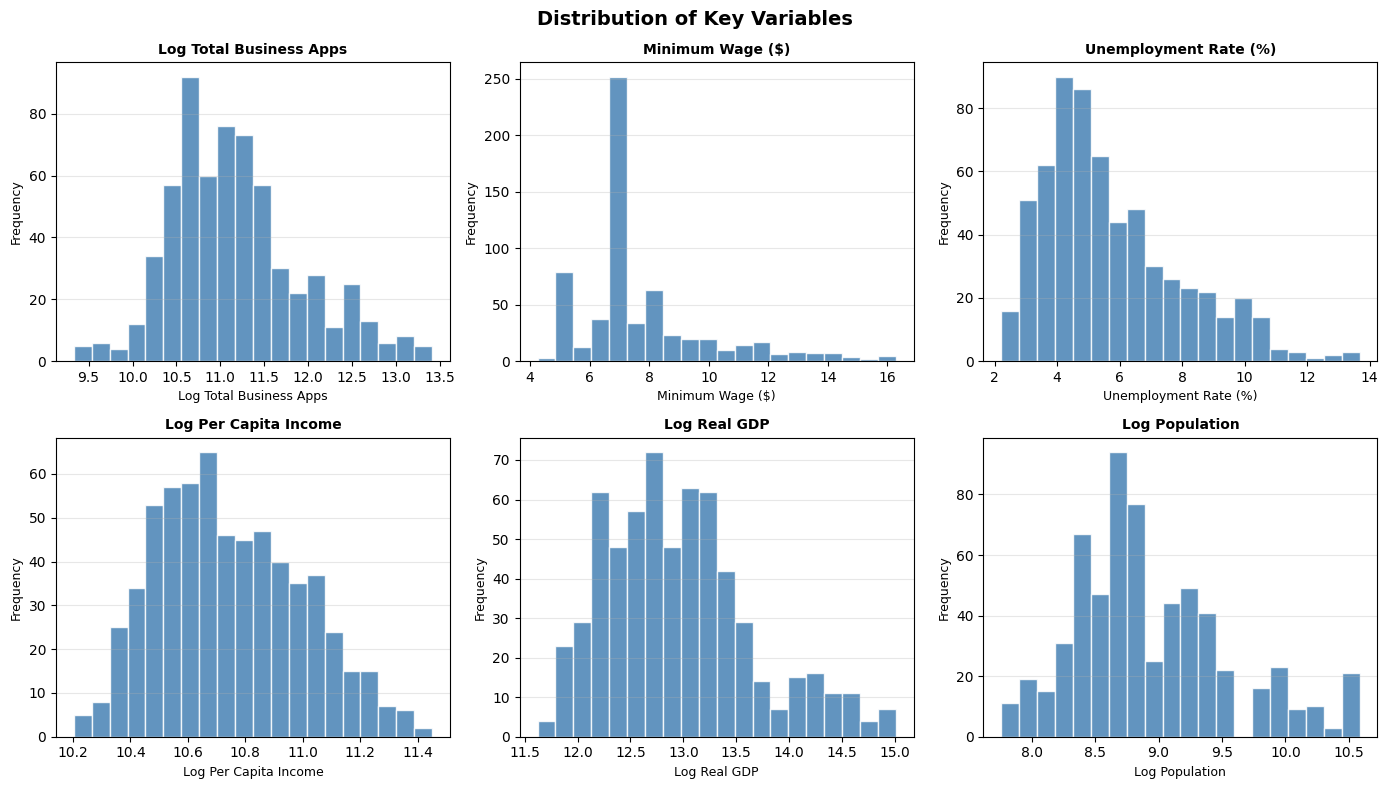

Saved: eda_distributions.png


In [ ]:
# Variable distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle("Distribution of Key Variables", fontsize=14, fontweight="bold")
plot_vars = [
    ("log_business_apps",     "Log Total Business Apps"),
    ("min_wage",              "Minimum Wage ($)"),
    ("unemployment_rate",     "Unemployment Rate (%)"),
    ("log_per_capita_income", "Log Per Capita Income"),
    ("log_real_gdp",          "Log Real GDP"),
    ("log_population",        "Log Population"),
]
for ax, (var, label) in zip(axes.flat, plot_vars):
    ax.hist(df[var].dropna(), bins=20, color="steelblue",
            edgecolor="white", alpha=0.85)
    ax.set_title(label, fontsize=10, fontweight="bold")
    ax.set_xlabel(label, fontsize=9)
    ax.set_ylabel("Frequency", fontsize=9)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: eda_distributions.png")

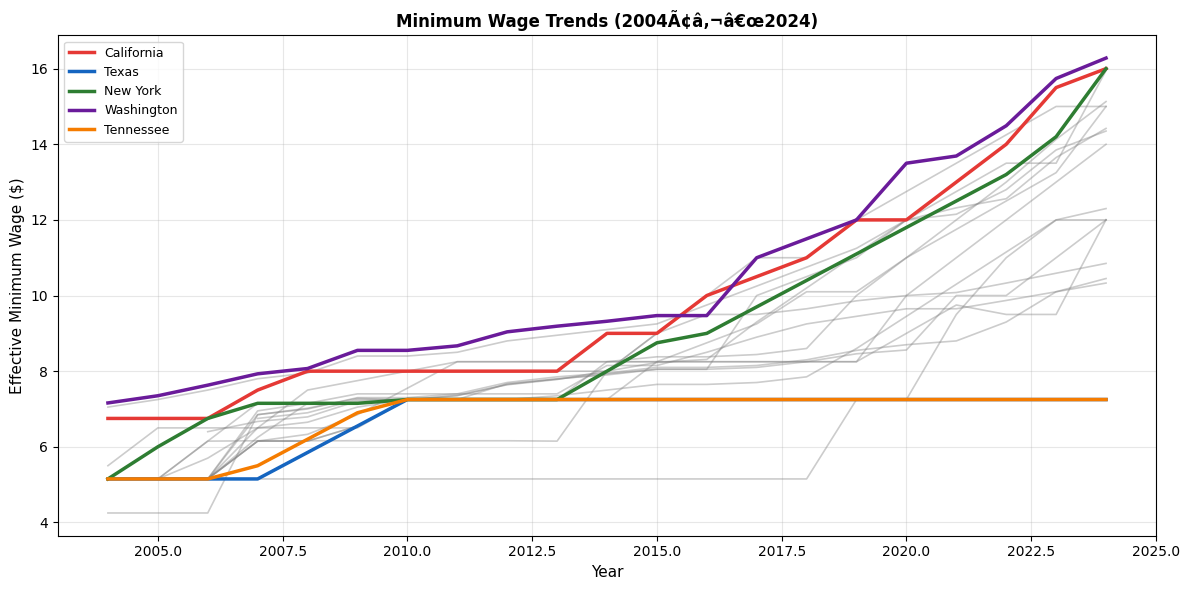

Saved: wage_trends.png


In [ ]:
# Minimum wage trends
fig, ax = plt.subplots(figsize=(12, 6))
for state in df["state"].unique():
    sub = df[df["state"] == state]
    ax.plot(sub["year"], sub["min_wage"], alpha=0.4, lw=1.2, color="grey")
for state, color in {"California":"#E53935","Texas":"#1565C0",
                     "New York":"#2E7D32","Washington":"#6A1B9A",
                     "Tennessee":"#F57C00"}.items():
    if state in df["state"].values:
        sub = df[df["state"]==state]
        ax.plot(sub["year"], sub["min_wage"], color=color,
                lw=2.5, label=state, zorder=5)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Effective Minimum Wage ($)", fontsize=11)
ax.set_title(f"Minimum Wage Trends ({df['year'].min()}-{df['year'].max()})",
             fontsize=12, fontweight="bold")
ax.legend(loc="upper left", fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("wage_trends.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: wage_trends.png")

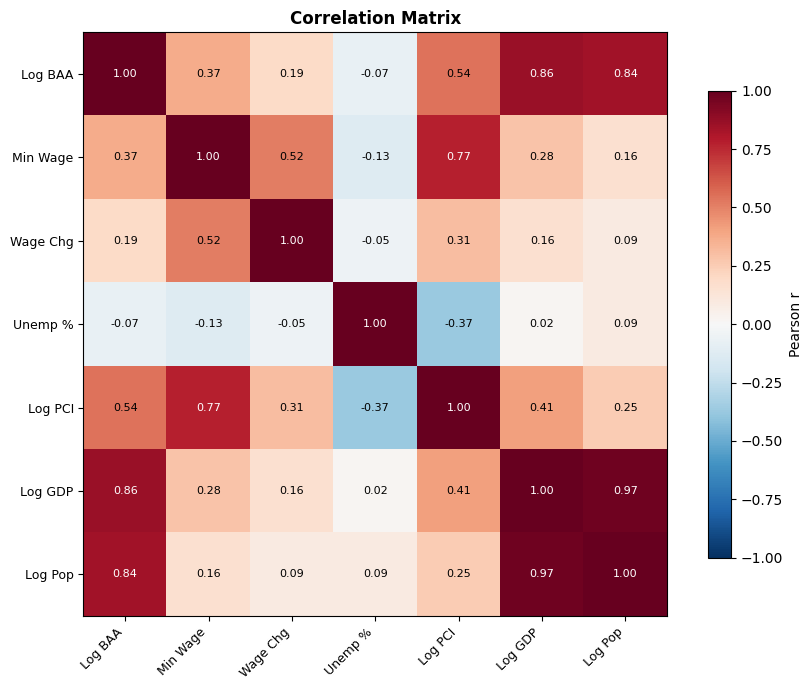

Saved: correlation_heatmap.png


In [ ]:
# Correlation heatmap
cvars  = ["log_business_apps","min_wage","wage_change",
          "unemployment_rate","log_per_capita_income",
          "log_real_gdp","log_population"]
labels = ["Log BAA","Min Wage","Wage Chg",
          "Unemp %","Log PCI","Log GDP","Log Pop"]
cm = df[cvars].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(labels, fontsize=9)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = cm.iloc[i,j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                fontsize=8, color="white" if abs(v)>0.6 else "black")
ax.set_title("Correlation Matrix", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: correlation_heatmap.png")

In [ ]:
# Model 1: pooled OLS with clustered SEs
# State clustering allows arbitrary serial correlation within states.
# With about 30 clusters, small-sample corrections and cautious p-value
# interpretation are important.

def fit_clustered(formula, data, cluster_col="state"):
    return smf.ols(formula, data=data).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": data[cluster_col],
            "use_correction": True,
            "df_correction": True,
        },
        use_t=True,
    )

def visible_terms(model):
    table = model.summary2().tables[1]
    return table[~table.index.str.startswith("C(")]

cluster_count = df["state"].nunique()
print(f"State clusters after merging: {cluster_count}")
if cluster_count < 30:
    print("WARNING: fewer than 30 state clusters remain after merging; inference may be fragile.")

model1 = fit_clustered(
    "log_business_apps ~ min_wage + wage_change",
    data=df,
)
print("="*65)
print("MODEL 1: Baseline OLS - state-clustered SE")
print("="*65)
print(visible_terms(model1).round(4))
print(f"\nR^2: {model1.rsquared:.4f}  |  N: {int(model1.nobs)}")


State clusters after merging: 30
MODEL 1: Baseline OLS - state-clustered SE
               Coef.  Std.Err.        t   P>|t|  [0.025   0.975]
Intercept    10.1879    0.2772  36.7503  0.0000  9.6209  10.7549
min_wage      0.1245    0.0349   3.5658  0.0013  0.0531   0.1958
wage_change  -0.0015    0.0505  -0.0288  0.9773 -0.1047   0.1018

R^2: 0.1365  |  N: 624


In [ ]:
# Model 2: two-way fixed effects
model2 = fit_clustered(
    "log_business_apps ~ min_wage + wage_change + C(state) + C(year)",
    data=df,
)
print("="*65)
print("MODEL 2: Two-Way FE - No Controls")
print("="*65)
print(visible_terms(model2).round(4))
print(f"\nR^2: {model2.rsquared:.4f}  |  N: {int(model2.nobs)}")


MODEL 2: Two-Way FE - No Controls
              Coef.  Std.Err.         t   P>|t|  [0.025  0.975]
Intercept    9.6258    0.0348  276.2266  0.0000  9.5545  9.6970
min_wage    -0.0282    0.0076   -3.6947  0.0009 -0.0438 -0.0126
wage_change  0.0144    0.0100    1.4408  0.1604 -0.0061  0.0349

R^2: 0.9916  |  N: 624


In [ ]:
# Model 3: two-way fixed effects with controls (main model)
main_formula = (
    "log_business_apps ~ "
    "min_wage + wage_change + "
    "log_real_gdp + unemployment_rate + "
    "log_per_capita_income + log_population + "
    "C(state) + C(year)"
)
model3 = fit_clustered(main_formula, data=df)
print("="*65)
print("MODEL 3: Two-Way FE + Controls (MAIN)")
print("="*65)
print(visible_terms(model3).round(4))
print(f"\nR^2: {model3.rsquared:.4f}  |  N: {int(model3.nobs)}")


MODEL 3: Two-Way FE + Controls (MAIN)
                        Coef.  Std.Err.       t   P>|t|  [0.025   0.975]
Intercept              6.2436    3.3966  1.8382  0.0763 -0.7032  13.1904
min_wage              -0.0269    0.0062 -4.3528  0.0002 -0.0395  -0.0142
wage_change            0.0116    0.0093  1.2502  0.2212 -0.0074   0.0305
log_real_gdp           0.3116    0.3559  0.8756  0.3884 -0.4163   1.0395
unemployment_rate     -0.0185    0.0085 -2.1825  0.0373 -0.0359  -0.0012
log_per_capita_income -0.2850    0.3369 -0.8460  0.4045 -0.9741   0.4041
log_population         0.3118    0.5675  0.5495  0.5869 -0.8488   1.4725

R^2: 0.9927  |  N: 624


In [ ]:
# Model 4: high-propensity applications
df_hba = df.dropna(subset=["log_hba"]).copy()
print(f"HBA rows: {len(df_hba)} ({df_hba['state'].nunique()} states)")
if len(df_hba) > 50 and df_hba["state"].nunique() >= 25:
    model4 = fit_clustered(
        "log_hba ~ "
        "min_wage + wage_change + "
        "log_real_gdp + unemployment_rate + "
        "log_per_capita_income + log_population + "
        "C(state) + C(year)",
        data=df_hba,
    )
    print("="*65)
    print("MODEL 4: Robustness - High-Propensity Applications")
    print("="*65)
    print(visible_terms(model4).round(4))
    print(f"\nR^2: {model4.rsquared:.4f}  |  N: {int(model4.nobs)}")
    HBA_OK = True
else:
    print("Insufficient HBA data or state coverage. Model 3 is the main result.")
    model4 = None
    HBA_OK = False


HBA rows: 624 (30 states)
MODEL 4: Robustness - High-Propensity Applications
                        Coef.  Std.Err.       t   P>|t|  [0.025   0.975]
Intercept              5.5476    3.5429  1.5659  0.1282 -1.6983  12.7936
min_wage              -0.0257    0.0062 -4.1238  0.0003 -0.0385  -0.0130
wage_change            0.0062    0.0073  0.8513  0.4016 -0.0087   0.0211
log_real_gdp           0.6002    0.4096  1.4654  0.1536 -0.2375   1.4380
unemployment_rate     -0.0075    0.0082 -0.9130  0.3687 -0.0243   0.0093
log_per_capita_income  0.0776    0.3046  0.2547  0.8008 -0.5455   0.7006
log_population        -0.5431    0.6847 -0.7932  0.4341 -1.9435   0.8573

R^2: 0.9929  |  N: 624


In [ ]:
# Robustness: lagged wage, state trends, results table
# Lagged policy variables reduce same-year reverse-causality concerns.
# State-specific linear trends reduce bias from slow-moving state trends,
# though they may absorb useful policy variation and widen confidence intervals.

df = df.sort_values(["state", "year"]).reset_index(drop=True)
df["lag_min_wage"] = df.groupby("state")["min_wage"].shift(1)
df["lag_wage_change"] = df.groupby("state")["wage_change"].shift(1)
df["year_centered"] = df["year"] - df["year"].min()

df_lag = df.dropna(subset=["lag_min_wage", "lag_wage_change"]).copy()
model5 = None
if len(df_lag) > 50 and df_lag["state"].nunique() >= 25:
    lag_formula = (
        "log_business_apps ~ "
        "lag_min_wage + lag_wage_change + "
        "log_real_gdp + unemployment_rate + "
        "log_per_capita_income + log_population + "
        "C(state) + C(year)"
    )
    model5 = fit_clustered(lag_formula, data=df_lag)
    print("="*65)
    print("MODEL 5: Lagged Minimum Wage Robustness")
    print("="*65)
    print(visible_terms(model5).round(4))
    print(f"\nR^2: {model5.rsquared:.4f}  |  N: {int(model5.nobs)}")

trend_formula = (
    "log_business_apps ~ "
    "min_wage + wage_change + "
    "log_real_gdp + unemployment_rate + "
    "log_per_capita_income + log_population + "
    "C(state) + C(year) + C(state):year_centered"
)
model6 = fit_clustered(trend_formula, data=df)
print("="*65)
print("MODEL 6: FE + Controls + State-Specific Linear Trends")
print("="*65)
print(visible_terms(model6).round(4))
print(f"\nR^2: {model6.rsquared:.4f}  |  N: {int(model6.nobs)}")


def fmt(m, variables):
    if isinstance(variables, str):
        variables = [variables]
    for v in variables:
        if v in m.params:
            c, se, p = m.params[v], m.bse[v], m.pvalues[v]
            s = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
            return f"{c:.4f}{s} ({se:.4f})"
    return "--"

models = [
    {"Model": "(1) Baseline", "obj": model1, "data": df, "outcome": "BAA", "timing": "Current", "state_fe": "No",  "year_fe": "No",  "trends": "No"},
    {"Model": "(2) FE Only", "obj": model2, "data": df, "outcome": "BAA", "timing": "Current", "state_fe": "Yes", "year_fe": "Yes", "trends": "No"},
    {"Model": "(3) FE+Controls", "obj": model3, "data": df, "outcome": "BAA", "timing": "Current", "state_fe": "Yes", "year_fe": "Yes", "trends": "No"},
]
if HBA_OK:
    models.append({"Model": "(4) HBA", "obj": model4, "data": df_hba, "outcome": "HBA", "timing": "Current", "state_fe": "Yes", "year_fe": "Yes", "trends": "No"})
if model5 is not None:
    models.append({"Model": "(5) Lagged", "obj": model5, "data": df_lag, "outcome": "BAA", "timing": "Lagged 1y", "state_fe": "Yes", "year_fe": "Yes", "trends": "No"})
models.append({"Model": "(6) State Trends", "obj": model6, "data": df, "outcome": "BAA", "timing": "Current", "state_fe": "Yes", "year_fe": "Yes", "trends": "Yes"})

rows = []
for spec in models:
    m = spec["obj"]
    d = spec["data"]
    rows.append({
        "Model": spec["Model"],
        "Outcome": spec["outcome"],
        "Policy timing": spec["timing"],
        "Min Wage": fmt(m, ["min_wage", "lag_min_wage"]),
        "Wage Chg": fmt(m, ["wage_change", "lag_wage_change"]),
        "Log GDP": fmt(m, "log_real_gdp"),
        "Unemp": fmt(m, "unemployment_rate"),
        "Log PCI": fmt(m, "log_per_capita_income"),
        "Log Pop": fmt(m, "log_population"),
        "State FE": spec["state_fe"],
        "Year FE": spec["year_fe"],
        "State Trends": spec["trends"],
        "Clusters": d["state"].nunique(),
        "R^2": f"{m.rsquared:.4f}",
        "N": int(m.nobs),
    })

res = pd.DataFrame(rows).set_index("Model")
print("="*90)
print("RESULTS TABLE - copy into paper")
print("State-clustered SE with small-sample corrections. * p<0.10  ** p<0.05  *** p<0.01")
print("="*90)
print(res.to_string())
res.to_csv("results_table.csv")
print("\nSaved results_table.csv")


MODEL 5: Lagged Minimum Wage Robustness
                        Coef.  Std.Err.       t   P>|t|  [0.025   0.975]
Intercept              7.8555    3.4406  2.2832  0.0299  0.8188  14.8922
lag_min_wage          -0.0296    0.0073 -4.0627  0.0003 -0.0445  -0.0147
lag_wage_change        0.0137    0.0127  1.0790  0.2895 -0.0123   0.0398
log_real_gdp           0.3431    0.3483  0.9851  0.3327 -0.3693   1.0556
unemployment_rate     -0.0180    0.0088 -2.0514  0.0494 -0.0359  -0.0001
log_per_capita_income -0.3926    0.2990 -1.3127  0.1996 -1.0042   0.2191
log_population         0.3057    0.5787  0.5283  0.6013 -0.8778   1.4893

R^2: 0.9920  |  N: 594
MODEL 6: FE + Controls + State-Specific Linear Trends
                        Coef.  Std.Err.       t   P>|t|  [0.025   0.975]
Intercept              7.2192    3.5133  2.0548  0.0490  0.0336  14.4047
min_wage              -0.0152    0.0088 -1.7298  0.0943 -0.0332   0.0028
wage_change            0.0068    0.0105  0.6507  0.5204 -0.0146   0.0283
log_re

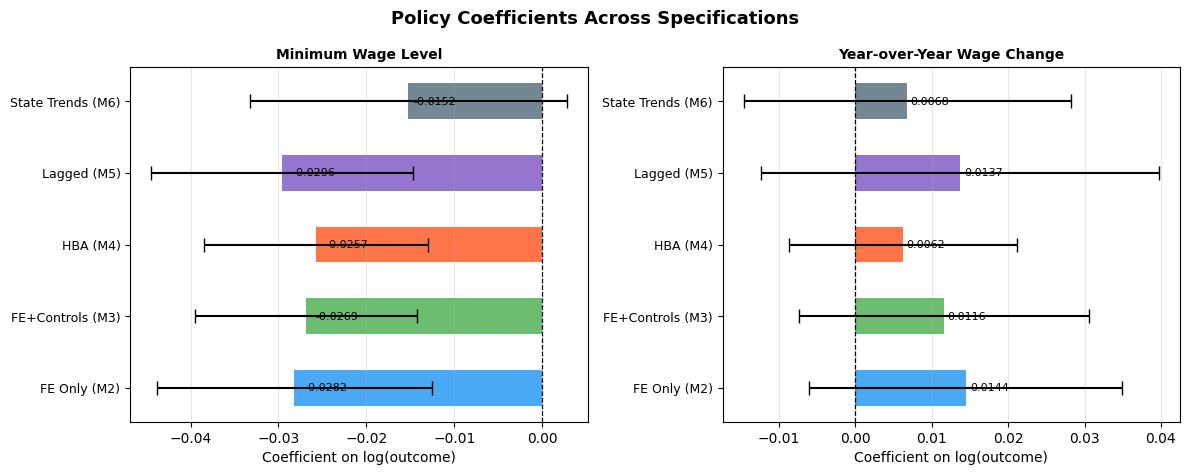

Saved: coefficient_comparison.png


In [ ]:
# Coefficient comparison plot
pms = [
    ("FE Only (M2)", model2, "min_wage", "wage_change", "#2196F3"),
    ("FE+Controls (M3)", model3, "min_wage", "wage_change", "#4CAF50"),
]
if HBA_OK:
    pms.append(("HBA (M4)", model4, "min_wage", "wage_change", "#FF5722"))
if model5 is not None:
    pms.append(("Lagged (M5)", model5, "lag_min_wage", "lag_wage_change", "#7E57C2"))
pms.append(("State Trends (M6)", model6, "min_wage", "wage_change", "#546E7A"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
fig.suptitle("Policy Coefficients Across Specifications", fontsize=13, fontweight="bold")
for ax, idx, lbl in zip(axes, [2, 3], ["Minimum Wage Level", "Year-over-Year Wage Change"]):
    for i, spec in enumerate(pms):
        nm, mo, min_var, chg_var, col = spec
        var = min_var if idx == 2 else chg_var
        if var not in mo.params:
            continue
        c = mo.params[var]
        ci = mo.conf_int().loc[var]
        ax.barh(i, c, color=col, alpha=0.82, height=0.5,
                xerr=[[c - ci[0]], [ci[1] - c]],
                error_kw={"lw": 1.5, "capsize": 5, "color": "black"})
        offset = 0.04 * max(abs(c), 0.01)
        ax.text(c + offset, i, f"{c:.4f}", va="center", fontsize=8)
    ax.axvline(0, color="black", lw=0.9, ls="--")
    ax.set_yticks(range(len(pms)))
    ax.set_yticklabels([m[0] for m in pms], fontsize=9)
    ax.set_title(lbl, fontsize=10, fontweight="bold")
    ax.set_xlabel("Coefficient on log(outcome)")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("coefficient_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: coefficient_comparison.png")


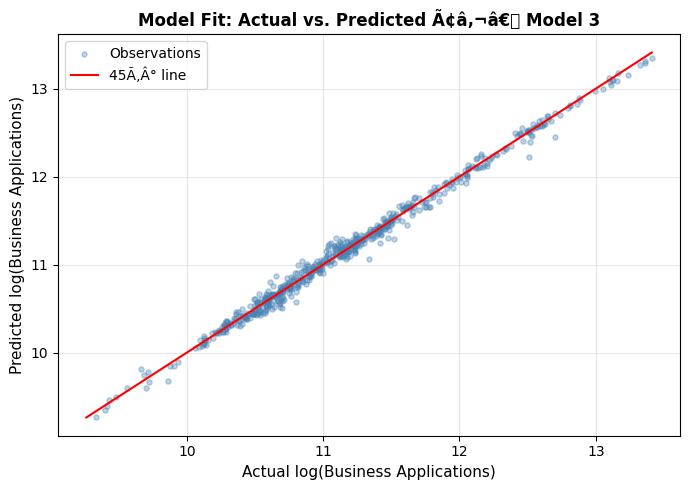

Saved: actual_vs_predicted.png


In [ ]:
# Actual vs. predicted
df["predicted"] = model3.predict(df)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["log_business_apps"], df["predicted"],
           alpha=0.35, s=14, color="steelblue", label="Observations")
mn = min(df["log_business_apps"].min(), df["predicted"].min())
mx = max(df["log_business_apps"].max(), df["predicted"].max())
ax.plot([mn,mx],[mn,mx], color="red", lw=1.5, label="45° line")
ax.set_xlabel("Actual log(Business Applications)", fontsize=11)
ax.set_ylabel("Predicted log(Business Applications)", fontsize=11)
ax.set_title("Model Fit: Actual vs. Predicted  -  Model 3",
             fontsize=12, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: actual_vs_predicted.png")

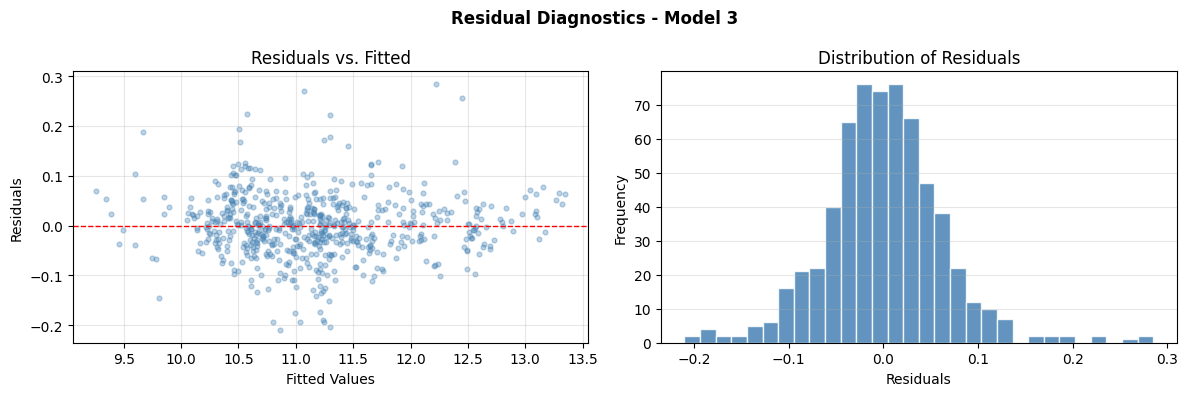

Saved: residual_diagnostics.png

Inference and identification diagnostics:
                       Diagnostic     Value                                                   Interpretation
                   State clusters 30.000000        Target is 30 or more for less fragile clustered inference
          Minimum years per state 18.000000                         Balanced/longer panels help FE estimates
           Median years per state 21.000000                            Shows typical within-state time depth
              Mean residual AR(1)  0.679038                         Moderate - state clustering is important
         Max absolute state AR(1)  0.933329 Large values indicate persistent residuals in at least one state
Future wage increase placebo coef -0.022693                                        WARNING: p-value = 0.0709

Saved inference_diagnostics.csv and state_residual_ar1.csv


In [ ]:
# Residual and inference diagnostics
df_diag = df.copy()
df_diag["model3_fitted"] = model3.predict(df_diag)
df_diag["model3_resid"] = df_diag["log_business_apps"] - df_diag["model3_fitted"]
fitted = df_diag["model3_fitted"]
resid = df_diag["model3_resid"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Residual Diagnostics - Model 3", fontsize=12, fontweight="bold")
axes[0].scatter(fitted, resid, alpha=0.35, s=12, color="steelblue")
axes[0].axhline(0, color="red", lw=1, ls="--")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs. Fitted")
axes[0].grid(alpha=0.3)
axes[1].hist(resid, bins=30, color="steelblue", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Residuals")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Residuals")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("residual_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: residual_diagnostics.png")

# Serial correlation diagnostic: average within-state AR(1) of residuals.
def ar1(x):
    x = x.dropna()
    if len(x) < 3:
        return np.nan
    return x.corr(x.shift(1))

state_ar1 = (
    df_diag.sort_values(["state", "year"])
    .groupby("state")["model3_resid"]
    .apply(ar1)
    .dropna()
)
mean_ar1 = state_ar1.mean() if len(state_ar1) else np.nan
max_abs_ar1 = state_ar1.abs().max() if len(state_ar1) else np.nan
if pd.isna(mean_ar1):
    serial_flag = "Not enough data"
elif abs(mean_ar1) >= 0.70:
    serial_flag = "High - rely on state-clustered SE and discuss limitation"
elif abs(mean_ar1) >= 0.40:
    serial_flag = "Moderate - state clustering is important"
else:
    serial_flag = "Low to moderate"

# Future-treatment placebo: if next year's wage increase predicts current
# applications, that is a warning sign for reverse causality/endogeneity.
df_placebo = df_diag.sort_values(["state", "year"]).copy()
df_placebo["future_wage_increase"] = df_placebo.groupby("state")["wage_increase"].shift(-1)
df_placebo = df_placebo.dropna(subset=["future_wage_increase"]).copy()
placebo_model = fit_clustered(
    "log_business_apps ~ future_wage_increase + "
    "log_real_gdp + unemployment_rate + "
    "log_per_capita_income + log_population + "
    "C(state) + C(year)",
    data=df_placebo,
)
placebo_coef = placebo_model.params.get("future_wage_increase", np.nan)
placebo_p = placebo_model.pvalues.get("future_wage_increase", np.nan)
placebo_flag = "PASS" if pd.notna(placebo_p) and placebo_p >= 0.10 else "WARNING"

cluster_sizes = df.groupby("state")["year"].nunique()
diag = pd.DataFrame([
    {"Diagnostic": "State clusters", "Value": df["state"].nunique(), "Interpretation": "Target is 30 or more for less fragile clustered inference"},
    {"Diagnostic": "Minimum years per state", "Value": int(cluster_sizes.min()), "Interpretation": "Balanced/longer panels help FE estimates"},
    {"Diagnostic": "Median years per state", "Value": float(cluster_sizes.median()), "Interpretation": "Shows typical within-state time depth"},
    {"Diagnostic": "Mean residual AR(1)", "Value": mean_ar1, "Interpretation": serial_flag},
    {"Diagnostic": "Max absolute state AR(1)", "Value": max_abs_ar1, "Interpretation": "Large values indicate persistent residuals in at least one state"},
    {"Diagnostic": "Future wage increase placebo coef", "Value": placebo_coef, "Interpretation": f"{placebo_flag}: p-value = {placebo_p:.4f}"},
])
print("\nInference and identification diagnostics:")
print(diag.to_string(index=False))
diag.to_csv("inference_diagnostics.csv", index=False)
state_ar1.rename("residual_ar1").to_csv("state_residual_ar1.csv")
print("\nSaved inference_diagnostics.csv and state_residual_ar1.csv")


---
## Output files

Running the notebook creates these files, which you can download from the Colab file browser:

- `panel_data_final.csv`, `results_table.csv`, `inference_diagnostics.csv`, `state_residual_ar1.csv`
- `eda_distributions.png`, `wage_trends.png`, `correlation_heatmap.png`, `coefficient_comparison.png`, `actual_vs_predicted.png`, `residual_diagnostics.png`

## How to read the results

The preferred specification is Model 3: state and year fixed effects, controls, and state-clustered standard errors. Because the data are observational, I read the estimates as associations conditional on those controls, not as proof of a causal effect. The lagged-wage model, the state-trend model, the residual serial-correlation check and the future-increase placebo test whether the main result holds up under different assumptions.
